In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from scipy import stats
from scipy.stats import chi2_contingency

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

In [ ]:
df = pd.read_csv('match_prediction_features.csv')
df.head()

,match_id,date,kickoff_time_utc,stage_id,is_knockout,home_team_id,home_team_name,home_fifa_code,home_confederation,away_team_id,...,home_prev_avg_xg_scored,home_prev_avg_xg_conceded,away_prev_avg_xg_scored,away_prev_avg_xg_conceded,home_score,away_score,result_type,home_xg,away_xg,match_result
0,1,6/11/2026,19:00,1,0,1,Mexico,MEX,CONCACAF,2,...,1.3,1.3,1.3,1.3,2.0,0.0,Regular,1.84,0.52,H
1,2,6/11/2026,23:00,1,0,3,South Korea,KOR,AFC,4,...,1.3,1.3,1.3,1.3,2.0,1.0,Regular,1.45,1.12,H
2,3,6/12/2026,19:00,1,0,5,Canada,CAN,CONCACAF,6,...,1.3,1.3,1.3,1.3,1.0,1.0,Regular,1.35,0.98,D
3,4,6/12/2026,23:00,1,0,13,USA,USA,CONCACAF,14,...,1.3,1.3,1.3,1.3,4.0,1.0,Regular,2.76,0.88,H
4,5,6/13/2026,15:00,1,0,7,Qatar,QAT,AFC,8,...,1.3,1.3,1.3,1.3,1.0,1.0,Regular,0.78,1.54,D


information of the dataframe

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 66 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   match_id                       100 non-null    int64  
 1   date                           100 non-null    object 
 2   kickoff_time_utc               100 non-null    object 
 3   stage_id                       100 non-null    int64  
 4   is_knockout                    100 non-null    int64  
 5   home_team_id                   100 non-null    int64  
 6   home_team_name                 100 non-null    object 
 7   home_fifa_code                 100 non-null    object 
 8   home_confederation             100 non-null    object 
 9   away_team_id                   100 non-null    int64  
 10  away_team_name                 100 non-null    object 
 11  away_fifa_code                 100 non-null    object 
 12  away_confederation             100 non-null    obje

In [ ]:
df.shape

(100, 66)

In [ ]:
df.describe()

,match_id,stage_id,is_knockout,home_team_id,away_team_id,venue_id,venue_capacity,venue_elevation_meters,referee_id,referee_avg_cards,...,home_prev_avg_offsides,away_prev_avg_offsides,home_prev_avg_xg_scored,home_prev_avg_xg_conceded,away_prev_avg_xg_scored,away_prev_avg_xg_conceded,home_score,away_score,home_xg,away_xg
count,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,...,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,97.000000,97.000000,97.000000,97.000000
mean,50.500000,1.44000,0.280000,23.860000,25.380000,8.670000,68191.720000,256.690000,9.690000,4.300000,...,1.679833,1.737333,1.52775,1.206087,1.427028,1.360573,1.721649,1.185567,1.563608,1.102887
std,29.011492,0.80804,0.451261,14.038921,13.799268,4.838931,12023.652478,552.621716,6.546948,0.592205,...,0.635078,0.606928,0.66823,0.528430,0.579969,0.660556,1.518924,1.166636,0.921908,0.703977
min,1.000000,1.00000,0.000000,1.000000,1.000000,1.000000,30000.000000,2.000000,1.000000,2.900000,...,0.000000,0.333333,0.26000,0.350000,0.350000,0.300000,0.000000,0.000000,0.130000,0.080000
25%,25.750000,1.00000,0.000000,12.000000,13.750000,4.000000,65878.000000,7.000000,4.000000,3.900000,...,1.333333,1.250000,1.19250,0.845000,1.110000,0.976250,1.000000,0.000000,0.850000,0.580000
50%,50.500000,1.00000,0.000000,24.000000,26.000000,9.000000,69796.000000,30.000000,8.500000,4.200000,...,2.000000,2.000000,1.30000,1.200000,1.300000,1.300000,1.000000,1.000000,1.450000,0.960000
75%,75.250000,2.00000,1.000000,36.250000,37.250000,13.000000,76416.000000,264.000000,14.000000,4.800000,...,2.000000,2.000000,1.86250,1.300000,1.817000,1.432500,3.000000,2.000000,2.120000,1.460000
max,100.000000,4.00000,1.000000,48.000000,48.000000,16.000000,82500.000000,2200.000000,28.000000,5.500000,...,3.000000,3.000000,4.82000,3.370000,3.335000,4.820000,7.000000,5.000000,4.820000,3.580000


#Data Cleaning


In [ ]:
print("Null values per coulmn")
print(df.isnull().sum())

Null values per coulmn
match_id            0
date                0
kickoff_time_utc    0
stage_id            0
is_knockout         0
                   ..
away_score          3
result_type         3
home_xg             3
away_xg             3
match_result        3
Length: 66, dtype: int64


In [ ]:
print("Duplicated data per rows: ")
print(df.duplicated().sum())

Duplicated data per rows: 
0


In [ ]:
df1 = df.copy()
df

,match_id,date,kickoff_time_utc,stage_id,is_knockout,home_team_id,home_team_name,home_fifa_code,home_confederation,away_team_id,...,home_prev_avg_xg_scored,home_prev_avg_xg_conceded,away_prev_avg_xg_scored,away_prev_avg_xg_conceded,home_score,away_score,result_type,home_xg,away_xg,match_result
0,1,6/11/2026,19:00,1,0,1,Mexico,MEX,CONCACAF,2,...,1.300,1.300,1.3000,1.300,2.0,0.0,Regular,1.84,0.52,H
1,2,6/11/2026,23:00,1,0,3,South Korea,KOR,AFC,4,...,1.300,1.300,1.3000,1.300,2.0,1.0,Regular,1.45,1.12,H
2,3,6/12/2026,19:00,1,0,5,Canada,CAN,CONCACAF,6,...,1.300,1.300,1.3000,1.300,1.0,1.0,Regular,1.35,0.98,D
3,4,6/12/2026,23:00,1,0,13,USA,USA,CONCACAF,14,...,1.300,1.300,1.3000,1.300,4.0,1.0,Regular,2.76,0.88,H
4,5,6/13/2026,15:00,1,0,7,Qatar,QAT,AFC,8,...,1.300,1.300,1.3000,1.300,1.0,1.0,Regular,0.78,1.54,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,7/7/2026,20:00,3,1,8,Switzerland,SUI,UEFA,44,...,1.805,0.935,1.8825,0.630,0.0,0.0,Penalties,1.15,1.46,D
96,97,7/9/2026,20:00,4,1,33,France,FRA,UEFA,10,...,2.116,0.754,1.3180,0.948,2.0,0.0,Regular,3.10,0.13,H
97,98,7/10/2026,19:00,4,1,29,Spain,ESP,UEFA,25,...,2.262,0.466,2.0340,1.294,NaN,NaN,NaN,NaN,NaN,NaN
98,99,7/11/2026,21:00,4,1,36,Norway,NOR,UEFA,45,...,1.834,1.376,1.8160,1.172,NaN,NaN,NaN,NaN,NaN,NaN


# Data Standarization

In [ ]:
#Z-Score:
scaler = StandardScaler()
df1[['home_elo']] = scaler.fit_transform(df1[['home_elo']])
df1[['away_elo']] = scaler.fit_transform(df1[['away_elo']])
df1[['home_prev_avg_possession']] = scaler.fit_transform(df1[['home_prev_avg_possession']])
df1[['away_prev_avg_possession']] = scaler.fit_transform(df1[['away_prev_avg_possession']])

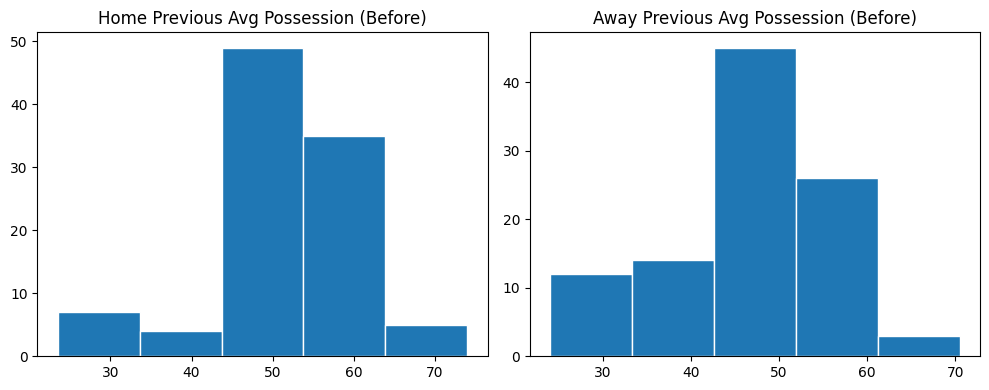

In [ ]:
#Before standardization
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df['home_prev_avg_possession'], bins=5, edgecolor='white')
axes[0].set_title('Home Previous Avg Possession (Before)')
axes[1].hist(df['away_prev_avg_possession'], bins=5, edgecolor='white')
axes[1].set_title('Away Previous Avg Possession (Before)')

plt.tight_layout()
plt.show()

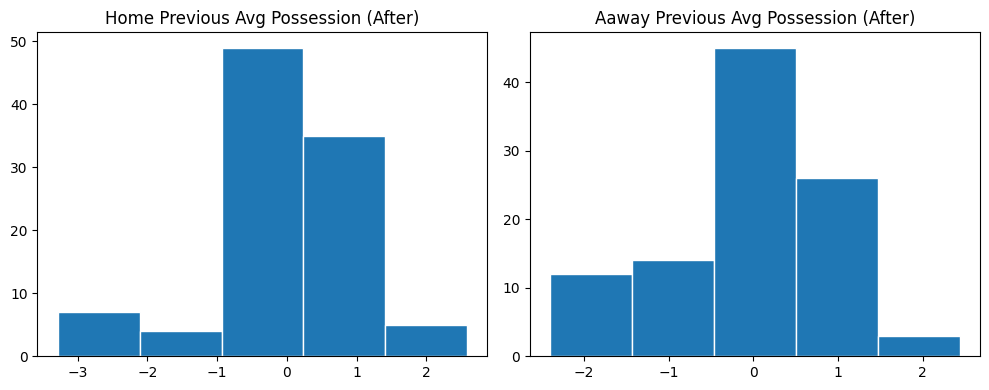

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df1['home_prev_avg_possession'], bins=5, edgecolor='white')
axes[0].set_title('Home Previous Avg Possession (After)')
axes[1].hist(df1['away_prev_avg_possession'], bins=5, edgecolor='white')
axes[1].set_title('Aaway Previous Avg Possession (After)')

plt.tight_layout()
plt.show()

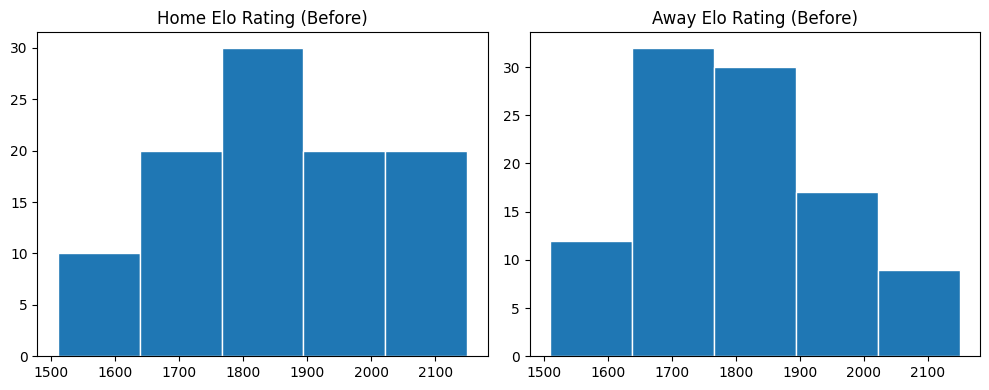

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df['home_elo'], bins=5, edgecolor='white')
axes[0].set_title('Home Elo Rating (Before)')
axes[1].hist(df['away_elo'], bins=5, edgecolor='white')
axes[1].set_title('Away Elo Rating (Before)')

plt.tight_layout()
plt.show()

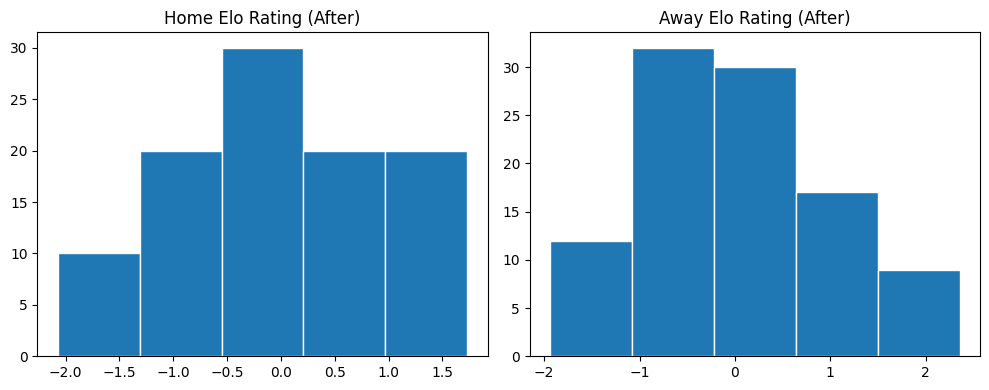

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(df1['home_elo'], bins=5, edgecolor='white')
axes[0].set_title('Home Elo Rating (After)')
axes[1].hist(df1['away_elo'], bins=5, edgecolor='white')
axes[1].set_title('Away Elo Rating (After)')

plt.tight_layout()
plt.show()

In [ ]:
scaler = MinMaxScaler()

# We use .values.reshape(-1, 1) to make it a 2D array for the scaler
df1['home_fifa_rank_normalized'] = scaler.fit_transform(df1['home_fifa_rank'].values.reshape(-1, 1))

# Check the results
print(df1[['home_fifa_rank', 'home_fifa_rank_normalized']].head())

   home_fifa_rank  home_fifa_rank_normalized
0              14                   0.154762
1              22                   0.250000
2              33                   0.380952
3              17                   0.190476
4              56                   0.654762


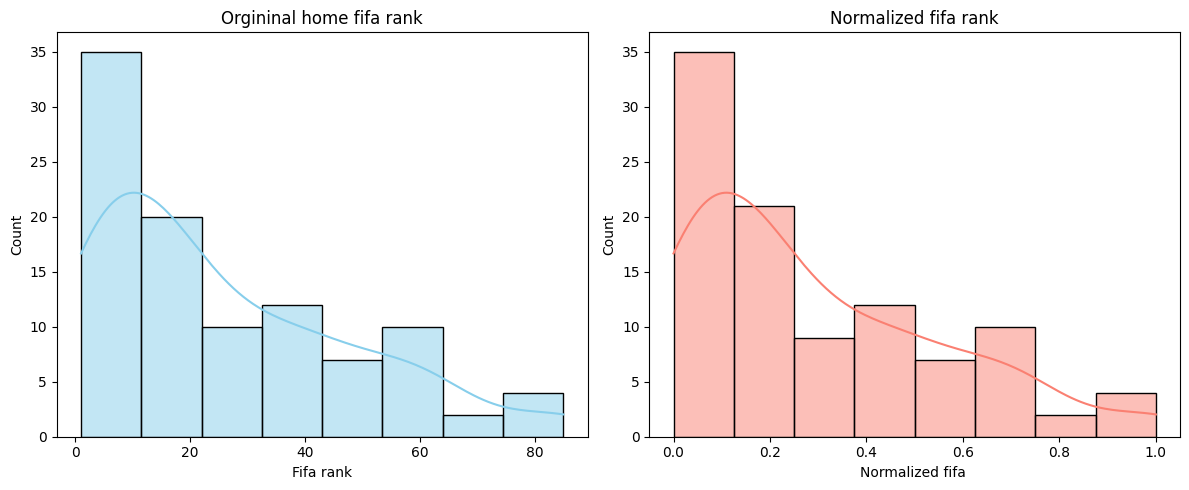

In [ ]:
# Set up a side-by-side plot
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Plot 1: Original Home_fifa_rank Column
sns.histplot(df1['home_fifa_rank'], kde=True, ax=ax1, color='skyblue')
ax1.set_title('Orgininal home fifa rank')
ax1.set_xlabel('Fifa rank')

# Plot 2: Normalized Home_fifa_rank Column
sns.histplot(df1['home_fifa_rank_normalized'], kde=True, ax=ax2, color='salmon')
ax2.set_title('Normalized fifa rank')
ax2.set_xlabel('Normalized fifa ')

plt.tight_layout()
plt.show()

In [ ]:
# We use .values.reshape(-1, 1) to make it a 2D array for the scaler
df1['referee_avg_cards_normalized'] = scaler.fit_transform(df1['referee_avg_cards'].values.reshape(-1, 1))

# Check the results
print(df1[['referee_avg_cards', 'referee_avg_cards_normalized']].head())

   referee_avg_cards  referee_avg_cards_normalized
0                4.2                      0.500000
1                4.8                      0.730769
2                3.9                      0.384615
3                4.1                      0.461538
4                3.6                      0.269231


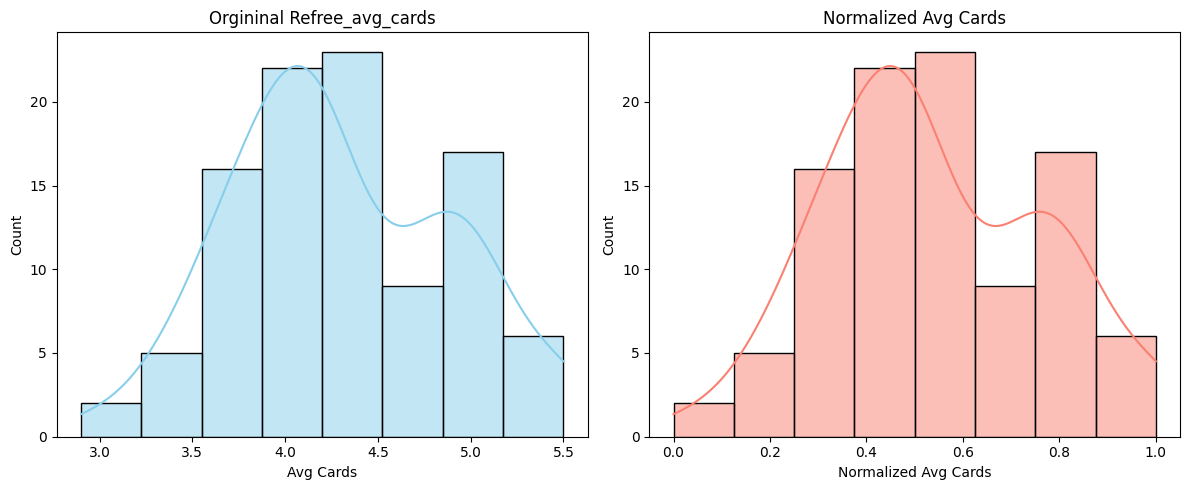

In [ ]:
# Set up a side-by-side plot
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# Plot 1: Original Refree Avg Cards Column
sns.histplot(df1['referee_avg_cards'], kde=True, ax=ax1, color='skyblue')
ax1.set_title('Orgininal Refree_avg_cards')
ax1.set_xlabel('Avg Cards')

# Plot 2: Normalized Refree Avg Cards Column
sns.histplot(df1['referee_avg_cards_normalized'], kde=True, ax=ax2, color='salmon')
ax2.set_title('Normalized Avg Cards')
ax2.set_xlabel('Normalized Avg Cards')

plt.tight_layout()
plt.show()

In [ ]:
# We use .values.reshape(-1, 1) to make it a 2D array for the scaler
df1['home_prev_avg_shots_normalized'] = scaler.fit_transform(df1['home_prev_avg_shots'].values.reshape(-1, 1))

# Check the results
print(df1[['home_prev_avg_shots', 'home_prev_avg_shots_normalized']].head())

   home_prev_avg_shots  home_prev_avg_shots_normalized
0                 12.0                        0.283019
1                 12.0                        0.283019
2                 12.0                        0.283019
3                 12.0                        0.283019
4                 12.0                        0.283019


In [ ]:
# We use .values.reshape(-1, 1) to make it a 2D array for the scaler
df1['away_prev_avg_shots_normalized'] = scaler.fit_transform(df1['away_prev_avg_shots'].values.reshape(-1, 1))

# Check the results
print(df1[['away_prev_avg_shots', 'away_prev_avg_shots_normalized']].head())

   away_prev_avg_shots  away_prev_avg_shots_normalized
0                 12.0                            0.45
1                 12.0                            0.45
2                 12.0                            0.45
3                 12.0                            0.45
4                 12.0                            0.45


In [ ]:
#Log Transformation
print('Before:')
print(df[['home_squad_total_value_eur', 'away_squad_total_value_eur']].head())

df1['home_squad_total_value_eur'] = np.log(df1['home_squad_total_value_eur'])
df1['away_squad_total_value_eur'] = np.log(df1['away_squad_total_value_eur'])

print('After:')
print(df1[['away_squad_total_value_eur', 'away_squad_total_value_eur']].head())

Before:
   home_squad_total_value_eur  away_squad_total_value_eur
0                   411906509                    47700000
1                   139050000                   187141830
2                   204233523                   146400000
3                   378812045                   135683726
4                   121299976                   357184518
After:
   away_squad_total_value_eur  away_squad_total_value_eur
0                   17.680442                   17.680442
1                   19.047377                   19.047377
2                   18.801853                   18.801853
3                   18.725837                   18.725837
4                   19.693763                   19.693763


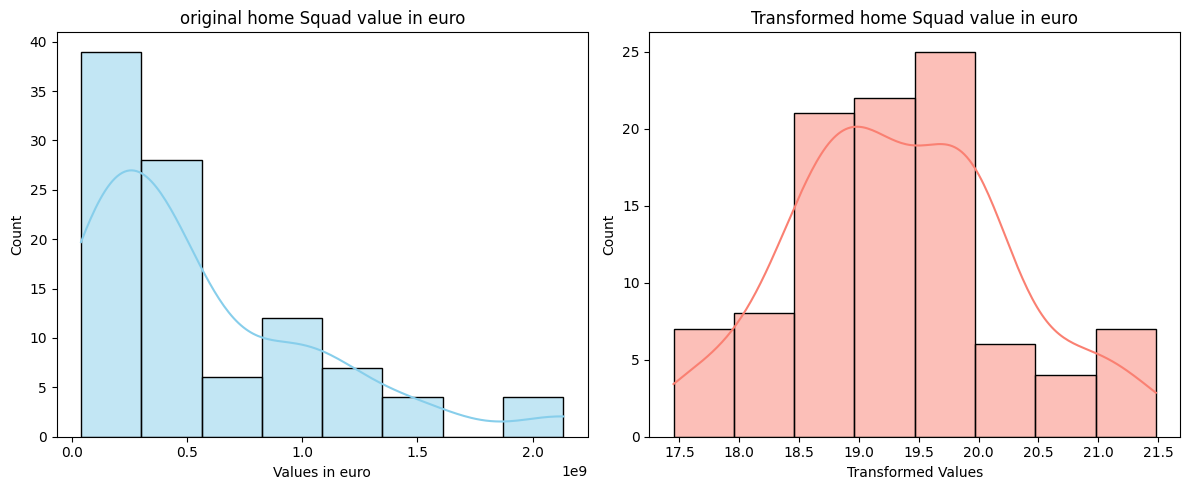

In [ ]:
# Set up a side-by-side plot
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))


sns.histplot(df['home_squad_total_value_eur'], kde=True, ax=ax1, color='skyblue')
ax1.set_title('original home Squad value in euro')
ax1.set_xlabel('Values in euro')


sns.histplot(df1['away_squad_total_value_eur'], kde=True, ax=ax2, color='salmon')
ax2.set_title('Transformed home Squad value in euro')
ax2.set_xlabel('Transformed Values')

plt.tight_layout()
plt.show()

#Data Visualization

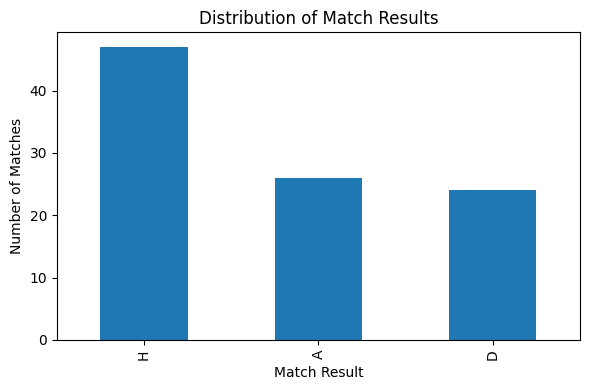

In [ ]:
plt.figure(figsize=(6,4))

df['match_result'].value_counts().plot(kind='bar')

plt.title("Distribution of Match Results")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

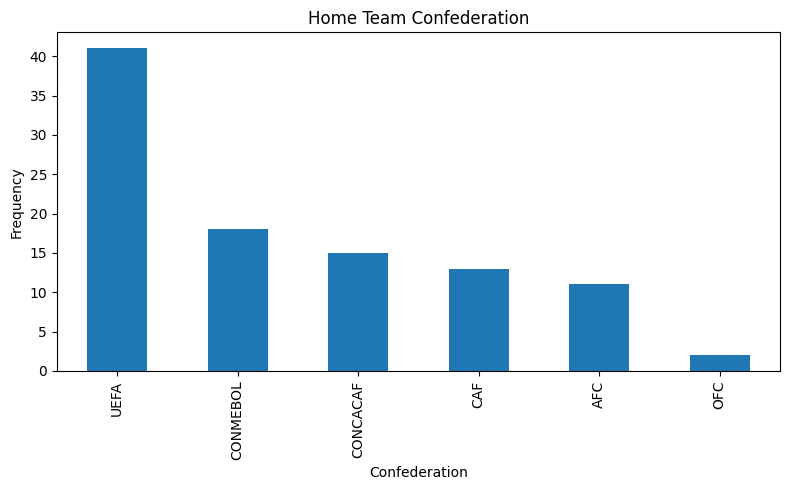

In [ ]:
plt.figure(figsize=(8,5))

df['home_confederation'].value_counts().plot(kind='bar')

plt.title("Home Team Confederation")
plt.xlabel("Confederation")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

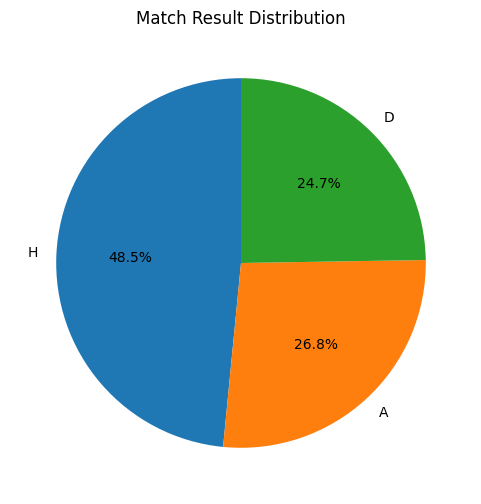

In [ ]:
plt.figure(figsize=(6,6))

df['match_result'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.ylabel("")
plt.title("Match Result Distribution")

plt.show()

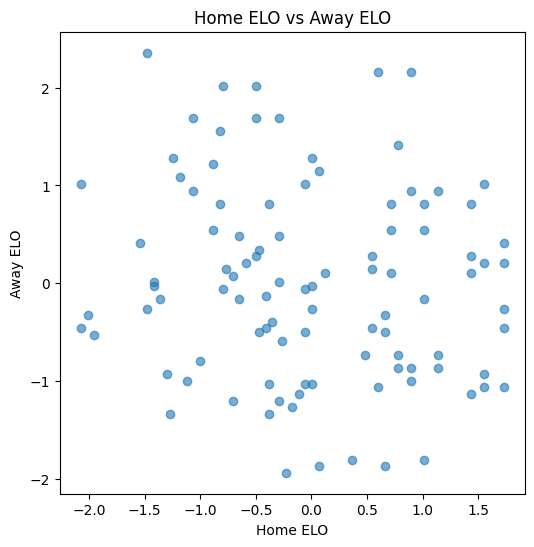

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(
    df1['home_elo'],
    df1['away_elo'],
    alpha=0.6
)

plt.title("Home ELO vs Away ELO")
plt.xlabel("Home ELO")
plt.ylabel("Away ELO")

plt.show()

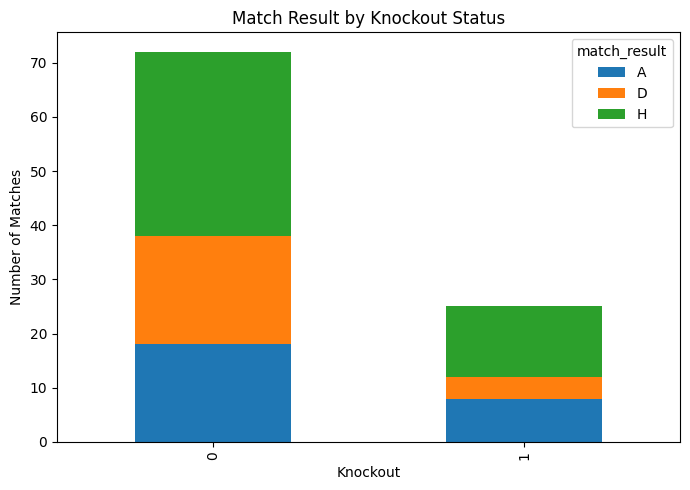

In [ ]:
table = pd.crosstab(
    df['is_knockout'],
    df['match_result']
)

table.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.title("Match Result by Knockout Status")
plt.xlabel("Knockout")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

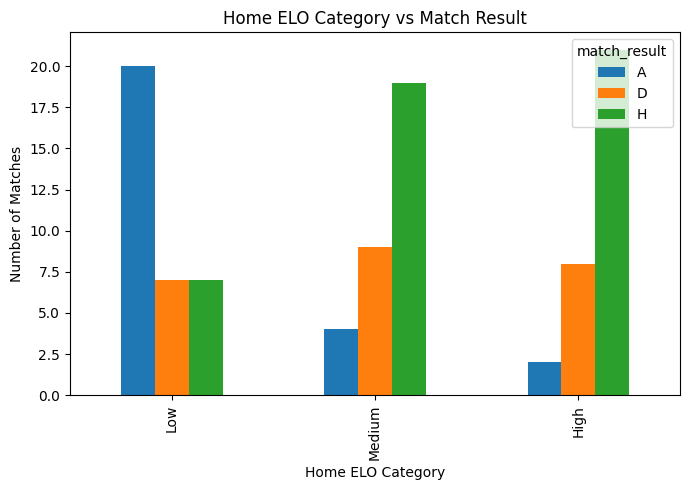

In [ ]:
df['home_elo_3tier'] = pd.qcut(
    df['home_elo'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

table = pd.crosstab(
    df['home_elo_3tier'],
    df['match_result']
)

table.plot(
    kind='bar',
    figsize=(7,5)
)

plt.title("Home ELO Category vs Match Result")
plt.xlabel("Home ELO Category")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

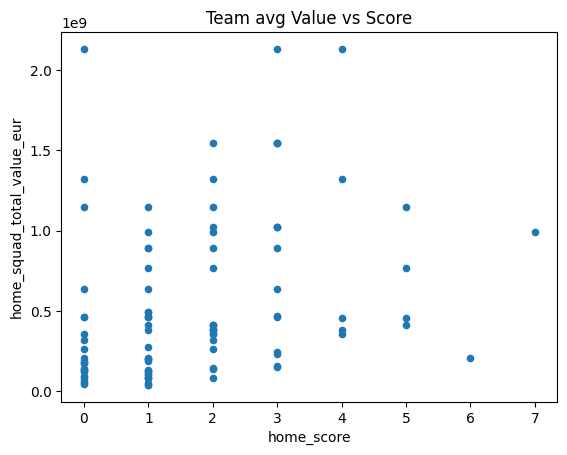

In [ ]:
# 2. Generate scatter plot
df.plot.scatter(x='home_score', y='home_squad_total_value_eur', title='Team avg Value vs Score')

# 3. Render the visualization
plt.show()

# Correlation Analysis

r =  -0.928 

p =  0.0 



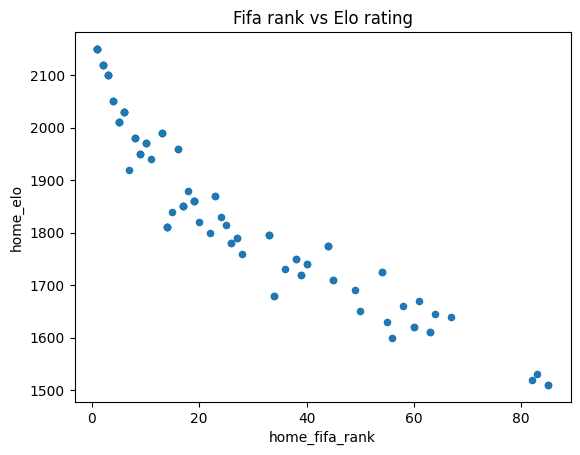

Reject the null hypothesis. There is a statistically significant correlation.


In [ ]:
#Pearson's correlation
r, p1 = stats.pearsonr (df1["home_fifa_rank"], df1["home_elo"])
print("r = ", r.round(4), "\n")
print("p = ", p1.round(4), "\n")

# 2. Generate scatter plot
df.plot.scatter(x='home_fifa_rank', y='home_elo', title='Fifa rank vs Elo rating')

# 3. Render the visualization
plt.show()

if p1 < 0.05:
    print("Reject the null hypothesis. There is a statistically significant correlation.")
else:
    print("Fail to reject the null hypothesis. There is no statistically significant correlation.")

r =  0.6051 

p =  0.0 



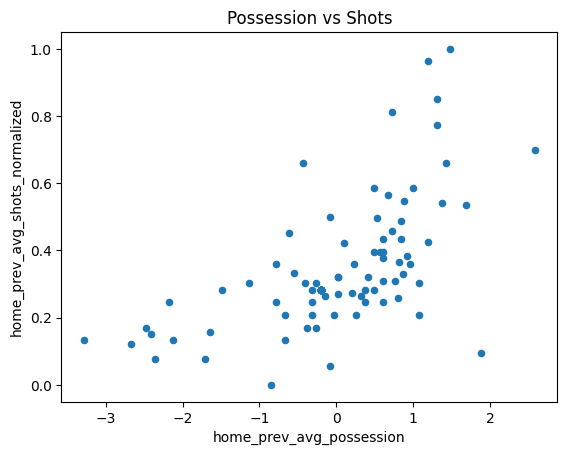

Result: STATISTICALLY SIGNIFICANT.
Conclusion: There is a significant positive relationship.


In [ ]:
#Pearson's correlation
r, p1 = stats.pearsonr (df1["home_prev_avg_possession"], df1["home_prev_avg_shots_normalized"])
print("r = ", r.round(4), "\n")
print("p = ", p1.round(4), "\n")

# 2. Generate scatter plot
df1.plot.scatter(x='home_prev_avg_possession', y='home_prev_avg_shots_normalized', title='Possession vs Shots')

# 3. Render the visualization
plt.show()

if p_value < 0.05:
    print("Result: STATISTICALLY SIGNIFICANT.")
    if r_coefficient > 0:
         print(f"Conclusion: There is a significant positive relationship.")
    else:
         print(f"Conclusion: There is a significant negative relationship.")
else:
    print("Result: NOT STATISTICALLY SIGNIFICANT.")
    print("Conclusion: There is no strong evidence of a linear relationship.")

Number of Data Points (Teams): 200
Pearson's Correlation Coefficient (r): 0.1776
P-value: 1.1874e-02
Result: STATISTICALLY SIGNIFICANT.
Conclusion: There is a significant positive relationship. Teams that average more corners tend to score more goals.


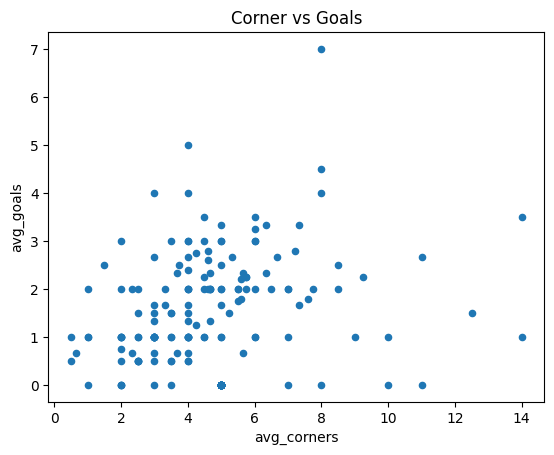

In [ ]:
# 2. Extract and combine Home and Away stats into a single DataFrame
home_stats = df[['home_prev_avg_corners', 'home_prev_avg_goals_scored']].copy()
home_stats.columns = ['avg_corners', 'avg_goals']

away_stats = df[['away_prev_avg_corners', 'away_prev_avg_goals_scored']].copy()
away_stats.columns = ['avg_corners', 'avg_goals']

# Merge them together and drop missing rows
team_stats = pd.concat([home_stats, away_stats], ignore_index=True).dropna()

# 3. Calculate Pearson's Correlation
r_coefficient, p_value = stats.pearsonr (team_stats['avg_corners'], team_stats['avg_goals'])

# 4. Print the statistical report
print(f"Number of Data Points (Teams): {len(team_stats)}")
print(f"Pearson's Correlation Coefficient (r): {r_coefficient:.4f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("Result: STATISTICALLY SIGNIFICANT.")
    if r_coefficient > 0:
         print(f"Conclusion: There is a significant positive relationship. Teams that average more corners tend to score more goals.")
    else:
         print(f"Conclusion: There is a significant negative relationship.")
else:
    print("Result: NOT STATISTICALLY SIGNIFICANT.")
    print("Conclusion: There is no strong evidence of a linear relationship between average corners and average goals scored.")

# 2. Generate scatter plot
team_stats.plot.scatter(x='avg_corners', y='avg_goals', title='Corner vs Goals')
# 3. Render the visualization
plt.show()


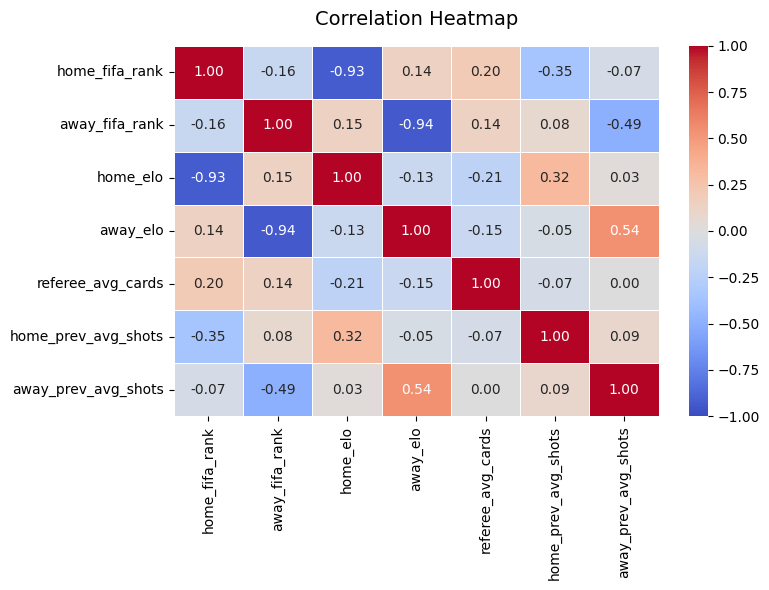

In [ ]:
# 2. Define the list of particular columns you want to analyze
selected_columns = [
    'home_fifa_rank',
    'away_fifa_rank',
    'home_elo',
    'away_elo',
    'referee_avg_cards',
    'home_prev_avg_shots',
    'away_prev_avg_shots'
]

# 3. Filter the DataFrame and calculate the correlation matrix
# This creates a square matrix showing how each selected feature relates to every other
corr_matrix = df[selected_columns].corr()

# 4. Set up the matplotlib plot layout
fig, ax = plt.subplots(figsize=(8, 6))

# 5. Create the heatmap
sns.heatmap(
    corr_matrix,          # The correlation data
    annot=True,           # Show the exact correlation numbers inside the squares
    cmap='coolwarm',      # The color gradient (blue for negative, red for positive)
    fmt=".2f",            # Round numbers to 2 decimal places
    linewidths=0.5,       # Add a small gap between squares for cleaner visuals
    vmin=-1, vmax=1,      # Forces the colorbar bounds between -1 and 1
    ax=ax
)

# 6. Add a title and adjust labels so they don't get cut off
ax.set_title('Correlation Heatmap', fontsize=14, pad=15)
plt.tight_layout()

plt.savefig('correlation heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# 3. Define bins using log-scale thresholds
log_bins = [0, np.log(100_000_000), np.log(500_000_000), np.log(1_000_000_000), float('inf')]
labels = ['Under €100M (Log < 18.42)', '€100M - €500M (Log 18.42 - 20.03)', '€500M - €1B (Log 20.03 - 20.72)', 'Over €1B (Log > 20.72)']

# 4. Perform the binning
df1['home_log_value_bin'] = pd.cut(df1['home_squad_total_value_eur'], bins=log_bins, labels=labels)
df1['away_log_value_bin'] = pd.cut(df1['away_squad_total_value_eur'], bins=log_bins, labels=labels)

print(df1[['home_squad_total_value_eur', 'home_log_value_bin']].head())
print('\n')
print(df1[['away_squad_total_value_eur', 'away_log_value_bin']].head())

   home_squad_total_value_eur                 home_log_value_bin
0                   19.836307  €100M - €500M (Log 18.42 - 20.03)
1                   18.750344  €100M - €500M (Log 18.42 - 20.03)
2                   19.134775  €100M - €500M (Log 18.42 - 20.03)
3                   19.752551  €100M - €500M (Log 18.42 - 20.03)
4                   18.613777  €100M - €500M (Log 18.42 - 20.03)


   away_squad_total_value_eur                 away_log_value_bin
0                   17.680442          Under €100M (Log < 18.42)
1                   19.047377  €100M - €500M (Log 18.42 - 20.03)
2                   18.801853  €100M - €500M (Log 18.42 - 20.03)
3                   18.725837  €100M - €500M (Log 18.42 - 20.03)
4                   19.693763  €100M - €500M (Log 18.42 - 20.03)


# Sample T-Test:

In [ ]:
#Q: does the team having a higher ELO rating translates to low referee cards?

df['match_avg_elo'] = (df['home_elo'] + df['away_elo']) / 2

# 3. Create two groups based on the median of referee average cards (Median = 4.2)
median_cards = df['referee_avg_cards'].median()
low_cards_group = df[df['referee_avg_cards'] <= median_cards]['match_avg_elo']
high_cards_group = df[df['referee_avg_cards'] > median_cards]['match_avg_elo']

t_stat, p_val = stats.ttest_ind(low_cards_group, high_cards_group, equal_var=False)

print("--- Grouped by Cards (Comparing Elo) ---")
print(f"Mean Elo in Low Cards games: {low_cards_group.mean():.2f}")
print(f"Mean Elo in High Cards games: {high_cards_group.mean():.2f}")

print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4f}")

print('\n')
H0 = "The average Elo rating of matches with low-card referees is equal to the average Elo rating of matches with high-card referees"
H1 = "The average Elo rating of matches with low-card referees is different from the average Elo rating of matches with high-card referees"

if p_val < 0.05:
    print(f"Reject the null hypothesis. {H1}")
else:
    print(f"Fail to reject the null hypothesis. {H0}")

--- Grouped by Cards (Comparing Elo) ---
Mean Elo in Low Cards games: 1854.18
Mean Elo in High Cards games: 1793.87
T-statistic: 2.9435
P-value: 0.0041


Reject the null hypothesis. The average Elo rating of matches with low-card referees is different from the average Elo rating of matches with high-card referees


In [ ]:
#Q: Does the team with more international experience has more advantages over the newer teams?

home = df[['home_team_name', 'home_squad_avg_age', 'home_squad_total_caps']].copy()
home.columns = ['team_name', 'squad_avg_age', 'squad_total_caps']

away = df[['away_team_name', 'away_squad_avg_age', 'away_squad_total_caps']].copy()
away.columns = ['team_name', 'squad_avg_age', 'squad_total_caps']

teams_df = pd.concat([home, away], ignore_index=True).drop_duplicates()

# 3. Create the Youth vs. Older split using the median age (27.84 years)
median_age = teams_df['squad_avg_age'].median()
youth_group_caps = teams_df[teams_df['squad_avg_age'] <= median_age]['squad_total_caps']
older_group_caps = teams_df[teams_df['squad_avg_age'] > median_age]['squad_total_caps']

# 4. Perform the Two-Sample Welch's T-Test
t_stat, p_val = stats.ttest_ind(youth_group_caps, older_group_caps, equal_var=False)

print(f"--- Experience (Caps) vs. Youth (Age) ---")
print(f"Median Squad Age Split: {median_age:.2f} years")
print("\n")
print(f"Mean Caps of Younger (Youth) Squads: {youth_group_caps.mean():.1f}")
print(f"Mean Caps of Older Squads: {older_group_caps.mean():.1f}")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_val:.4f}")

H0 = "The Older squads doesn't possess more international experience as the Younger squads"
H1 = "The Older squads have more international experience as the Younger squads"

print("\n")
if p_val < 0.05:
    print(f"Reject the null hypothesis. {H1}")
else:
    print(f"Fail to reject the null hypothesis. {H0}")

--- Experience (Caps) vs. Youth (Age) ---
Median Squad Age Split: 27.84 years


Mean Caps of Younger (Youth) Squads: 786.6
Mean Caps of Older Squads: 1032.9
T-statistic: -4.3081
P-value: 0.0001


Reject the null hypothesis. The Older squads have more international experience as the Younger squads


In [ ]:
#Q = Does the team with high value translate to the high elo rating?

# Combine home and away teams to create team-level data
home_val = df1[['home_team_name', 'home_squad_total_value_eur', 'home_elo']].copy()
home_val.columns = ['team_name', 'squad_total_value_eur', 'elo']

away_val = df1[['away_team_name', 'away_squad_total_value_eur', 'away_elo']].copy()
away_val.columns = ['team_name', 'squad_total_value_eur', 'elo']

# Combine and remove duplicate records of the same team to isolate team profiles
teams_val = pd.concat([home_val, away_val], ignore_index=True).drop_duplicates().dropna()

# Create two groups split at the median squad market value
median_val = teams_val['squad_total_value_eur'].median()
low_value_elo = teams_val[teams_val['squad_total_value_eur'] <= median_val]['elo']
high_value_elo = teams_val[teams_val['squad_total_value_eur'] > median_val]['elo']

t_stat_b, p_val_b = stats.ttest_ind(low_value_elo, high_value_elo, equal_var=False)

print(f"Median Squad Market Value: €{median_val:,.2f}")
print(f"Mean Elo of Low Value Squads: {low_value_elo.mean():.2f}")
print(f"Mean Elo of High Value Squads: {high_value_elo.mean():.2f}")
print('\n')

print(f"T-statistic: {t_stat_b:.4f}")
print(f"P-value: {p_val_b:.4f} \n")

H0 = "There is no significant difference in team Elo between low-value and high-value squads."
H1 = "High-value squads have a significantly different average Elo rating compared to low-value squads."

if p_val_b < 0.05:
    print(f"Reject the null hypothesis. {H1}")
else:
    print(f"Fail to reject the null hypothesis. {H0}")

Median Squad Market Value: €19.28
Mean Elo of Low Value Squads: -0.95
Mean Elo of High Value Squads: 0.63


T-statistic: -11.6890
P-value: 0.0000 

Reject the null hypothesis. High-value squads have a significantly different average Elo rating compared to low-value squads.


In [ ]:
#Q =

# Combine home and away teams to inspect tactical profiles
home_tac = df[['home_team_name', 'home_prev_avg_possession', 'home_prev_avg_fouls']].copy()
home_tac.columns = ['team_name', 'prev_avg_possession', 'prev_avg_fouls']

away_tac = df[['away_team_name', 'away_prev_avg_possession', 'away_prev_avg_fouls']].copy()
away_tac.columns = ['team_name', 'prev_avg_possession', 'prev_avg_fouls']

# Combine and remove duplicate records of the same team to isolate team profiles
teams_tac = pd.concat([home_tac, away_tac], ignore_index=True).drop_duplicates().dropna()

# Create two groups split at the median of average fouls
median_fouls = teams_tac['prev_avg_fouls'].median()
low_fouls_possession = teams_tac[teams_tac['prev_avg_fouls'] <= median_fouls]['prev_avg_possession']
high_fouls_possession = teams_tac[teams_tac['prev_avg_fouls'] > median_fouls]['prev_avg_possession']

# Run the Two-Sample Welch's T-Test
t_stat_d, p_val_d = stats.ttest_ind(low_fouls_possession, high_fouls_possession, equal_var=False)

print(f"Median of Match Average Fouls: {median_fouls:.2f} fouls")
print(f"Mean Possession of Low Foul Teams: {low_fouls_possession.mean():.2f}%")
print(f"Mean Possession of High Foul Teams: {high_fouls_possession.mean():.2f}%")
print(f"T-statistic: {t_stat_d:.4f}")
print(f"P-value: {p_val_d:.4f}")

H0_d = "There is no significant difference in possession percentage based on team fouling tendencies."
H1_d = "Teams that commit fewer fouls control significantly more possession."

if p_val_d < 0.05:
    print(f"Reject the null hypothesis. {H1_d}")
else:
    print(f"Fail to reject the null hypothesis. {H0_d}")

Median of Match Average Fouls: 11.75 fouls
Mean Possession of Low Foul Teams: 51.62%
Mean Possession of High Foul Teams: 47.14%
T-statistic: 3.4603
P-value: 0.0007
Reject the null hypothesis. Teams that commit fewer fouls control significantly more possession.


# Chi-Squared Test

In [ ]:
#Q = Is there any association between the Home Team Fifa rank and the match result?

df_clean = df.dropna(subset=['match_result', 'home_fifa_rank', 'home_elo']).copy()

def perform_chi2_analysis(df, var_name, category_col, test_title):
    print(f"\n==================================================")
    print(f"{test_title}")
    print(f"==================================================")

    # Generate cross-tabulation table
    contingency_table = pd.crosstab(df[category_col], df['match_result'])
    print("Contingency Table (Observed Counts):")
    print(contingency_table)

    # Calculate Chi-Squared Test
    chi2, p_val, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-Square Statistic: {chi2:.4f}")
    print(f"Degrees of Freedom: {dof}")
    print(f"P-value: {p_val:.4f}")

    if p_val < 0.05:
        print("Conclusion: REJECT the null hypothesis. There is a statistically significant association.")
    else:
        print("Conclusion: FAIL TO REJECT the null hypothesis. The variables are independent.")

# Splitting into 3 equal parts automatically
df_clean['home_fifa_rank_3tier'] = pd.qcut(df_clean['home_fifa_rank'], q=3, labels=['Top Tier', 'Middle Tier', 'Bottom Tier'])

perform_chi2_analysis(df_clean, 'home_fifa_rank', 'home_fifa_rank_3tier', "TEST 1A: Match Result x Home FIFA Rank")


TEST 1A: Match Result x Home FIFA Rank
Contingency Table (Observed Counts):
match_result           A  D   H
home_fifa_rank_3tier           
Top Tier               2  9  21
Middle Tier            5  9  20
Bottom Tier           19  6   6

Chi-Square Statistic: 29.3269
Degrees of Freedom: 4
P-value: 0.0000
Conclusion: REJECT the null hypothesis. There is a statistically significant association.


In [ ]:
#Q = Is there a significant association between the home team's ELO rating category and the match result?

df_clean = df.dropna(subset=['match_result', 'home_fifa_rank', 'home_elo']).copy()

def perform_chi2_analysis(df, var_name, category_col, test_title):
    print(f"\n==================================================")
    print(f"{test_title}")
    print(f"==================================================")

    # Generate cross-tabulation table
    contingency_table = pd.crosstab(df[category_col], df['match_result'])
    print("Contingency Table (Observed Counts):")
    print(contingency_table)

    # Calculate Chi-Squared Test
    chi2, p_val, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-Square Statistic: {chi2:.4f}")
    print(f"Degrees of Freedom: {dof}")
    print(f"P-value: {p_val:.4f}")

    if p_val < 0.05:
        print("Conclusion: REJECT the null hypothesis. There is a statistically significant association.")
    else:
        print("Conclusion: FAIL TO REJECT the null hypothesis. The variables are independent.")

# Splitting into 3 equal parts automatically
df_clean['home_elo_3tier'] = pd.qcut(df_clean['home_elo'], q=3, labels=['Low Elo', 'Medium Elo', 'High Elo'])


perform_chi2_analysis(df_clean, 'home_elo', 'home_elo_3tier', "TEST 2A: Match Result x Home ELO")


TEST 2A: Match Result x Home ELO
Contingency Table (Observed Counts):
match_result     A  D   H
home_elo_3tier           
Low Elo         20  7   7
Medium Elo       3  8  19
High Elo         3  9  21

Chi-Square Statistic: 28.7849
Degrees of Freedom: 4
P-value: 0.0000
Conclusion: REJECT the null hypothesis. There is a statistically significant association.


CHI-SQUARED TEST: HOME CONFEDERATION x AWAY CONFEDERATION

Observed Frequency Matrix:
away_confederation  AFC  CAF  CONCACAF  CONMEBOL  OFC  UEFA
home_confederation                                         
AFC                   0    2         0         3    1     5
CAF                   6    0         3         1    0     3
CONCACAF              3    3         0         2    0     7
CONMEBOL              2    7         2         0    0     7
OFC                   0    1         0         0    0     1
UEFA                  7   16         4         4    0    10

Chi-Square Statistic (chi^2): 37.7046
Degrees of Freedom (dof): 25
P-value: 0.0494
Result: REJECT the null hypothesis (Statistically Significant).
Meaning: The pairings between home and away confederations are NOT random.
Tournament draw restrictions/seeding rules structurally influence who plays whom.

Visualization matrix successfully saved as 'confederation_matchups_heatmap.png'


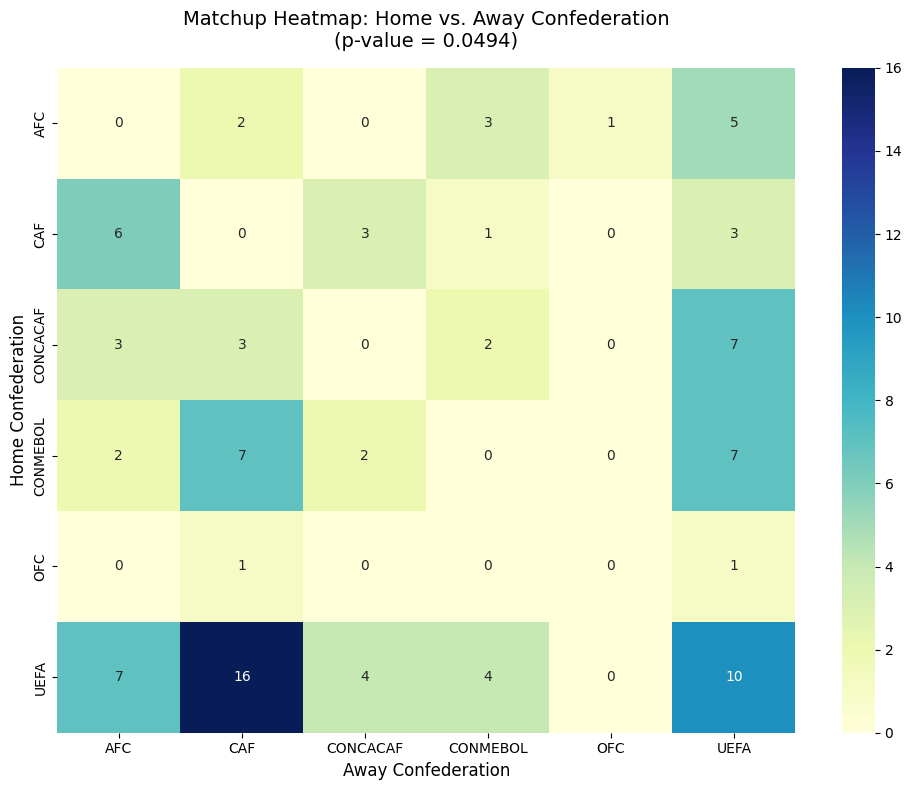

In [ ]:
#Q = Are the FIFA World Cup match pairings associated with the confederations of the home and away teams?

df_clean = df.dropna(subset=['home_confederation', 'away_confederation']).copy()

# 3. Generate the Cross-Tabulation (Contingency) Table
contingency_table = pd.crosstab(df_clean['home_confederation'], df_clean['away_confederation'])

# 4. Perform the Chi-Squared Test of Independence
chi2_stat, p_value, dof, expected_freqs = chi2_contingency(contingency_table)

# 5. Print out the formal statistical report
print("==========================================================")
print("CHI-SQUARED TEST: HOME CONFEDERATION x AWAY CONFEDERATION")
print("==========================================================")
print("\nObserved Frequency Matrix:")
print(contingency_table)

print(f"\nChi-Square Statistic (chi^2): {chi2_stat:.4f}")
print(f"Degrees of Freedom (dof): {dof}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Result: REJECT the null hypothesis (Statistically Significant).")
    print("Meaning: The pairings between home and away confederations are NOT random.")
    print("Tournament draw restrictions/seeding rules structurally influence who plays whom.")
else:
    print("Result: FAIL TO REJECT the null hypothesis (Not Statistically Significant).")
    print("Meaning: The pairings between home and away confederations are independent.")
    print("Matchups reflect a purely random continental distribution.")
print("==========================================================")

# 6. Create and save a visual Heatmap of the matrix
plt.figure(figsize=(10, 8))
sns.heatmap(contingency_table, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title('Matchup Heatmap: Home vs. Away Confederation\n(p-value = 0.0494)', fontsize=14, pad=15)
plt.xlabel('Away Confederation', fontsize=12)
plt.ylabel('Home Confederation', fontsize=12)
plt.tight_layout()

# Save the plot to your current working directory
plt.savefig('confederation_matchups_heatmap.png')
print("\nVisualization matrix successfully saved as 'confederation_matchups_heatmap.png'")

# Prediction using Random Forest

In [ ]:
# Split data into completed matches (Training/Testing) and upcoming matches (Validation)
completed_matches = df[df['match_result'].notna()].copy()
upcoming_matches = df[df['match_result'].isna()].copy()

print(f"-> Total Completed Matches for Training: {len(completed_matches)}")
print(f"-> Total Upcoming Matches to Predict: {len(upcoming_matches)}\n")

-> Total Completed Matches for Training: 97
-> Total Upcoming Matches to Predict: 3



In [ ]:
print("Input features...")

def engineer_match_features(dataframe):
    # Core mathematical difference features
    dataframe['elo_diff'] = dataframe['home_elo'] - dataframe['away_elo']
    dataframe['rank_diff'] = dataframe['home_fifa_rank'] - dataframe['away_fifa_rank']
    dataframe['value_ratio'] = dataframe['home_squad_total_value_eur'] / dataframe['away_squad_total_value_eur']

    # Statistical performance delta features
    dataframe['prev_goals_diff'] = dataframe['home_prev_avg_goals_scored'] - dataframe['away_prev_avg_goals_scored']
    dataframe['prev_xg_diff'] = dataframe['home_prev_avg_xg_scored'] - dataframe['away_prev_avg_xg_scored']
    dataframe['rest_days_diff'] = dataframe['home_rest_days'] - dataframe['away_rest_days']

    return dataframe

Input features...


In [ ]:
completed_matches = engineer_match_features(completed_matches)
upcoming_matches = engineer_match_features(upcoming_matches)

In [ ]:
# ==========================================
# STEP 4: MACHINE LEARNING MODEL TRAINING
# ==========================================
# Selecting our target variable and optimal predictive features
features = ['elo_diff', 'rank_diff', 'value_ratio', 'prev_goals_diff', 'prev_xg_diff', 'rest_days_diff']
X = completed_matches[features]
y = completed_matches['match_result']

# Splitting dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
print("raining Random Forest Classifier")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Model evaluation
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"\n Model Training Complete!")
print(f" Out-of-Sample Accuracy: {accuracy * 100:.2f}%\n")
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

raining Random Forest Classifier

 Model Training Complete!
 Out-of-Sample Accuracy: 45.00%

--- Classification Report ---
              precision    recall  f1-score   support

           A       0.67      0.80      0.73         5
           D       0.00      0.00      0.00         5
           H       0.56      0.50      0.53        10

    accuracy                           0.45        20
   macro avg       0.41      0.43      0.42        20
weighted avg       0.44      0.45      0.44        20



🎨 Plotting Diagram 3: Confusion Matrix...


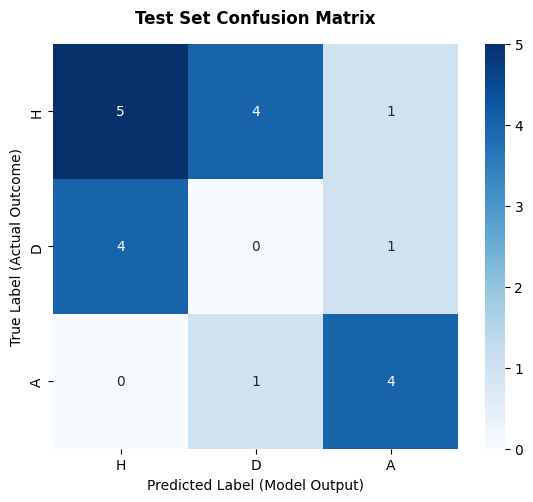

In [ ]:
# ==========================================
# DIAGRAM 3: CONFUSION MATRIX HEATMAP
# ==========================================
print("🎨 Plotting Diagram 3: Confusion Matrix...")
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred, labels=['H', 'D', 'A'])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['H', 'D', 'A'],
    yticklabels=['H', 'D', 'A'],
    cbar=True,
    square=True
)
plt.title('Test Set Confusion Matrix', weight='bold', pad=15)
plt.xlabel('Predicted Label (Model Output)')
plt.ylabel('True Label (Actual Outcome)')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
# ==========================================
# STEP 5: PREDICTING UPCOMING FIXTURES
# ==========================================
if len(upcoming_matches) > 0:
    print("Forecasting Future Match Outcomes...")
    X_upcoming = upcoming_matches[features]

    # Generate categorical outcome predictions and exact probabilities
    predictions = model.predict(X_upcoming)
    probabilities = model.predict_proba(X_upcoming)

    upcoming_matches['Predicted_Result'] = predictions
    upcoming_matches['Prob_Home_Win'] = probabilities[:, 2] # Index maps to classes 'H'
    upcoming_matches['Prob_Draw'] = probabilities[:, 1]     # Index maps to 'D'
    upcoming_matches['Prob_Away_Win'] = probabilities[:, 0]     # Index maps to 'A'

    # Display the final predictions clean matrix
    output_cols = ['home_team_name', 'away_team_name', 'Predicted_Result', 'Prob_Home_Win', 'Prob_Draw', 'Prob_Away_Win']
    print(upcoming_matches[output_cols].to_string(index=False))
else:
    print("No unplayed matches remaining to predict.")

Forecasting Future Match Outcomes...
home_team_name away_team_name Predicted_Result  Prob_Home_Win  Prob_Draw  Prob_Away_Win
         Spain        Belgium                H           0.70       0.19           0.11
        Norway        England                D           0.01       0.74           0.25
     Argentina    Switzerland                H           0.86       0.14           0.00


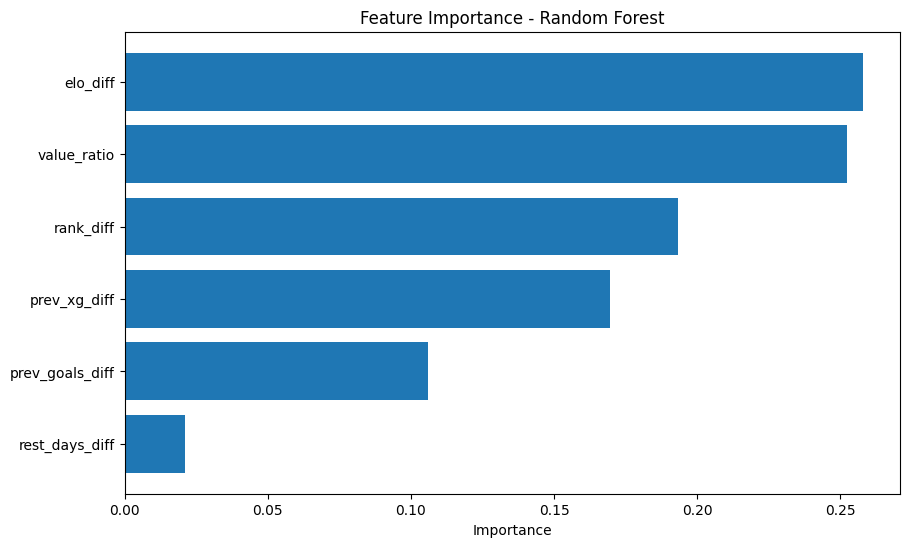

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values('Importance', ascending=False)

plt.figure(figsize=(10,6))
plt.barh(importance['Feature'], importance['Importance'])
plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.show()